In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load stock prices from CSV file
file_path = "/content/drive/MyDrive/MScDS&AI/RNN/1.StockData.csv"
stock_data = pd.read_csv(file_path)

days = stock_data['Day'].values
actual_stock_prices = stock_data['Stock Price ($)'].values
print(stock_data)

def tanh(x):
    return np.tanh(x)

   Day  Stock Price ($)
0    1              100
1    2              102
2    3              105
3    4              107


In [3]:
x_values = actual_stock_prices / 100  # Normalize by 100
print(x_values)
# --- Step 2: Initialize RNN parameters ---
Whx = 0.82   # Weight from input to hidden state
Whh = 0.7    # Recurrent weight
Why = 1.2    # Weight from hidden state to output

def tanh(x):
    return np.tanh(x)

# --- Step 3: Initialize hidden state ---
h0 = 0  # Initial hidden state


[1.   1.02 1.05 1.07]


In [4]:
# --- Step 4: Compute hidden states and outputs explicitly ---
# We store them in lists to make plotting easier later
hidden_states = []
outputs = []
losses = []

# Time Step 1
h1 = tanh(Whx * x_values[0] + Whh * h0)
y1 = Why * h1
loss1 = (y1 - x_values[1])**2
hidden_states.append(h1)
outputs.append(y1)
losses.append(loss1)

# Time Step 2
h2 = tanh(Whx * x_values[1] + Whh * h1)
y2 = Why * h2
loss2 = (y2 - x_values[2])**2
hidden_states.append(h2)
outputs.append(y2)
losses.append(loss2)

# Time Step 3
h3 = tanh(Whx * x_values[2] + Whh * h2)
y3 = Why * h3
loss3 = (y3 - x_values[3])**2
hidden_states.append(h3)
outputs.append(y3)
losses.append(loss3)

# Time Step 4
h4 = tanh(Whx * x_values[3] + Whh * h3)
y4 = Why * h4

hidden_states.append(h4)
outputs.append(y4)

# Compute total loss
total_loss = sum(losses)
predicted_price = y4 * 100  # Unnormalize last prediction


In [5]:
# --- Step 5: Print results ---
# Convert to standard Python floats to avoid np.float64 type display
print("Hidden states:", [float(h) for h in hidden_states])
print("Outputs:", [float(y) for y in outputs])
print("Loss at each step:", [float(l) for l in losses])
print("Total Loss:", float(total_loss))
print("Predicted stock price for next day:", round(predicted_price, 2))

Hidden states: [0.6750698748386078, 0.8640092165156918, 0.8987744661207676, 0.9063234832977515]
Outputs: [0.8100838498063293, 1.0368110598188303, 1.078529359344921, 1.0875881799573017]
Loss at each step: [0.04406479011213172, 0.00017394814310247485, 7.274997083479015e-05]
Total Loss: 0.044311488226068986
Predicted stock price for next day: 108.76


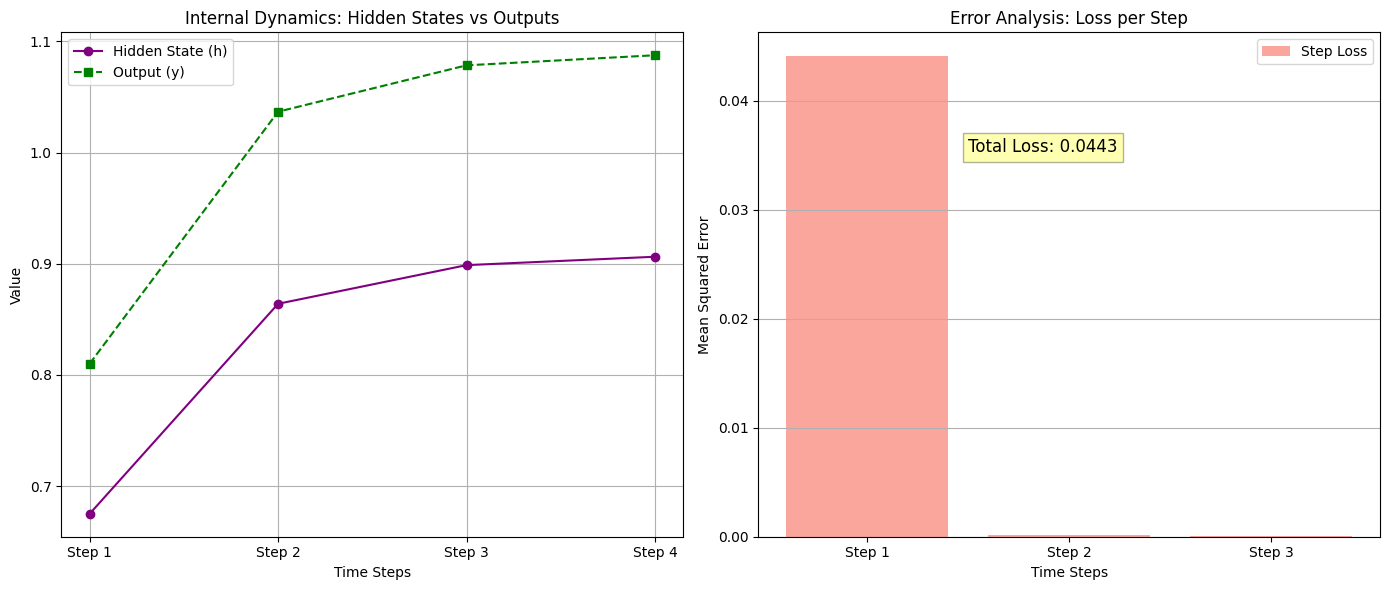

In [12]:
import matplotlib.pyplot as plt


steps = ['Step 1', 'Step 2', 'Step 3', 'Step 4']


plt.figure(figsize=(14, 6))

# --- Subplot 1: Hidden States vs Outputs (Length 4 matches Length 4) ---
plt.subplot(1, 2, 1)
plt.plot(steps, hidden_states, marker='o', linestyle='-', color='purple', label='Hidden State (h)')
plt.plot(steps, outputs, marker='s', linestyle='--', color='green', label='Output (y)')
plt.title('Internal Dynamics: Hidden States vs Outputs')
plt.xlabel('Time Steps')
plt.ylabel('Value')
plt.legend()
plt.grid(True)

# --- Subplot 2: Loss at each step (Length 3 matches Length 3) ---
plt.subplot(1, 2, 2)

# FIX: Slice 'steps' to match the length of 'losses' (Use only first 3 steps)
plt.bar(steps[:len(losses)], losses, color='salmon', alpha=0.7, label='Step Loss')

# Add Total Loss as text on the plot
# (Positioning text relative to the plot size for better visibility)
plt.text(0.5, max(losses) * 0.8, f'Total Loss: {total_loss:.4f}',
         fontsize=12, bbox=dict(facecolor='yellow', alpha=0.3))

plt.title('Error Analysis: Loss per Step')
plt.xlabel('Time Steps')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True, axis='y')

plt.tight_layout()
plt.show()

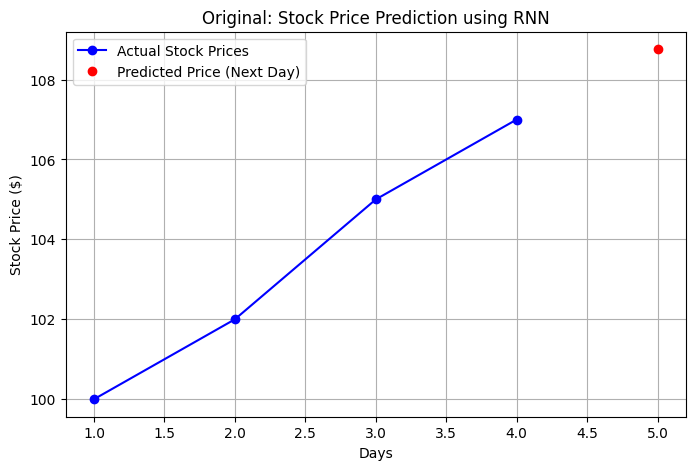

In [9]:
# Figure 2: The Original Prediction Plot
plt.figure(figsize=(8, 5))
plt.plot(days, actual_stock_prices, 'bo-', label="Actual Stock Prices")
plt.plot(days[-1] + 1, predicted_price, 'ro', label="Predicted Price (Next Day)")

plt.xlabel("Days")
plt.ylabel("Stock Price ($)")
plt.title("Original: Stock Price Prediction using RNN")
plt.legend()
plt.grid(True)

plt.show()


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
